# Implementace a experimenty: Hustotní shlukování DBSCAN – Soustředné kružnice

## 📋 Cíle cvičení a přednášky:
1. Prozkoumat fungování hustotního algoritmu **DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*).
2. Ukázat zásadní omezení algoritmu **K-Means** na nekonvexních (lineárně neseparabilních) strukturách, jako jsou soustředné kruhy vytvořené pomocí `sklearn.datasets.make_circles`.
3. Pochopit vliv dvou klíčových hyperparametrů: poloměru sousedství **`eps` ($arepsilon$)** a minimálního počtu sousedů **`min_samples`**.
4. Naučit se klasifikovat datové body do tří kategorií: **Core (jádrové)**, **Border (hraniční)** a **Noise (šum / odlehlé hodnoty označené jako `-1`)**.
5. Aplikovat objektivní metodu pro volbu parametru $\varepsilon$ pomocí grafu vzdáleností k nejbližšímu sousedovi (**k-NN distance graph**).

---  
### Krok 1: Import knihoven

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_circles
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print("Knihovny úspěšně načteny.")

Knihovny úspěšně načteny.


---  
### Krok 2: Generování soustředných kružnic a standardizace
Vytvoříme dataset 300 bodů tvořících dva soustředné prstence pomocí `make_circles(n_samples=300, factor=0.5, noise=0.1)`. Následně data standardizujeme pomocí `StandardScaler`.

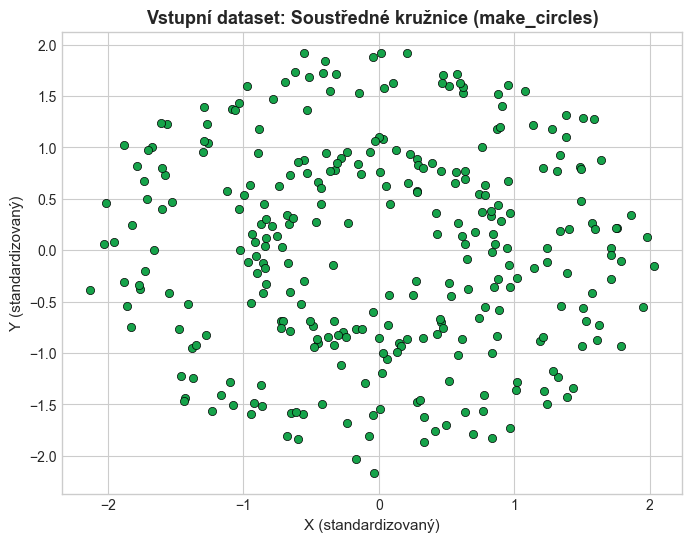

In [2]:
# 1. Generování soustředných kružnic přesně dle slajdů
data, labels_true = make_circles(n_samples=300, factor=0.5, noise=0.1, random_state=42)

# 2. Standardizace veličin
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

# 3. Vykreslení neoznačených vstupních dat
plt.figure(figsize=(8, 6))
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], color='#16a34a', marker='o', s=35, edgecolors='black', linewidth=0.5)
plt.title('Vstupní dataset: Soustředné kružnice (make_circles)', fontsize=13, fontweight='bold')
plt.xlabel('X (standardizovaný)', fontsize=11)
plt.ylabel('Y (standardizovaný)', fontsize=11)
plt.show()

---  
### Krok 3: Proč zde K-Means fatálně selhává?
Před spuštěním DBSCAN otestujeme chování algoritmu K-Means s nastavením $k = 2$. Centroidy K-Means se pokusí minimalizovat rozptyl a rozdělí data lineární hranicí (Voroného dělící nadrovinou), což oba kruhy nesmyslně rozetne napůl.

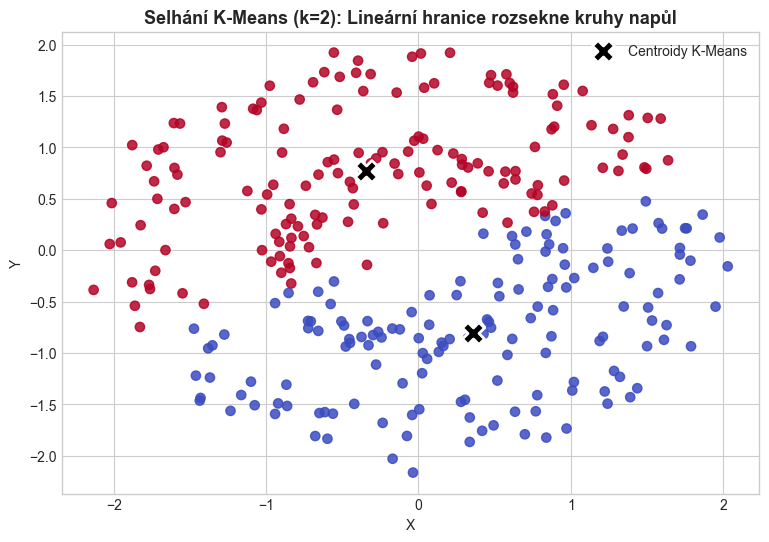

In [3]:
km = KMeans(n_clusters=2, init='k-means++', n_init=10, random_state=42)
km_labels = km.fit_predict(data_scaled)
centers = km.cluster_centers_

plt.figure(figsize=(9, 6))
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c=km_labels, cmap='coolwarm', s=45, alpha=0.85)
plt.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=250, edgecolors='white', linewidth=2, label='Centroidy K-Means')
plt.title('Selhání K-Means (k=2): Lineární hranice rozsekne kruhy napůl', fontsize=13, fontweight='bold')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

---  
### Krok 4: DBSCAN – Experimentování s parametry ze slajdů

#### Varianta A (Slajd 13): `eps = 0.40, min_samples = 15`
Při příliš přísném `min_samples = 15` a poloměru `0.40` algoritmus vytvoří více drobných shluků a označí část bodů jako šum.

Varianta A: Nalezeno shluků: 1, Detekováno bodů šumu: 149


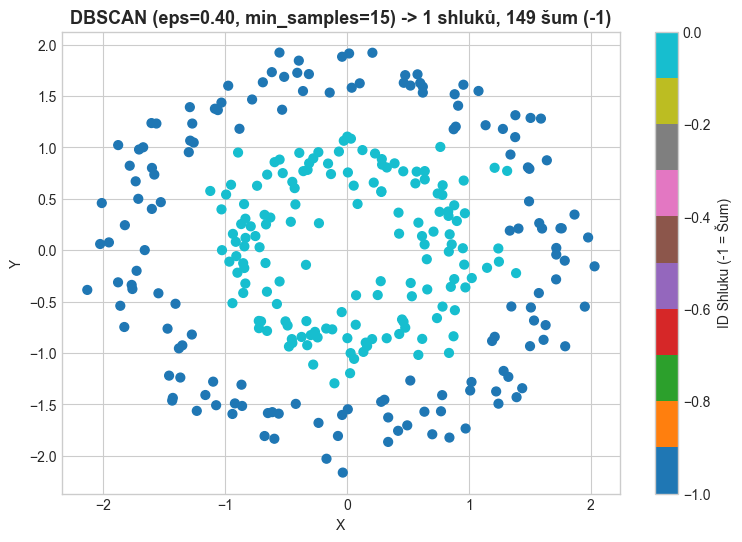

In [4]:
db_1 = DBSCAN(eps=0.40, min_samples=15)
labels_1 = db_1.fit_predict(data_scaled)

n_clusters_1 = len(set(labels_1)) - (1 if -1 in labels_1 else 0)
n_noise_1 = list(labels_1).count(-1)
print(f"Varianta A: Nalezeno shluků: {n_clusters_1}, Detekováno bodů šumu: {n_noise_1}")

plt.figure(figsize=(9, 6))
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c=labels_1, cmap='tab10', s=40)
plt.title(f'DBSCAN (eps=0.40, min_samples=15) -> {n_clusters_1} shluků, {n_noise_1} šum (-1)', fontsize=13, fontweight='bold')
plt.xlabel('X')
plt.ylabel('Y')
plt.colorbar(label='ID Shluku (-1 = Šum)')
plt.show()

#### Varianta B (Slajd 15): `eps = 0.25, min_samples = 10`
Při menším poloměru `eps = 0.25` algoritmus správně zachytí vnitřní kruh, ale vnější řidší kruh se částečně rozpadá do šumu.

Varianta B: Nalezeno shluků: 5, Detekováno bodů šumu: 192


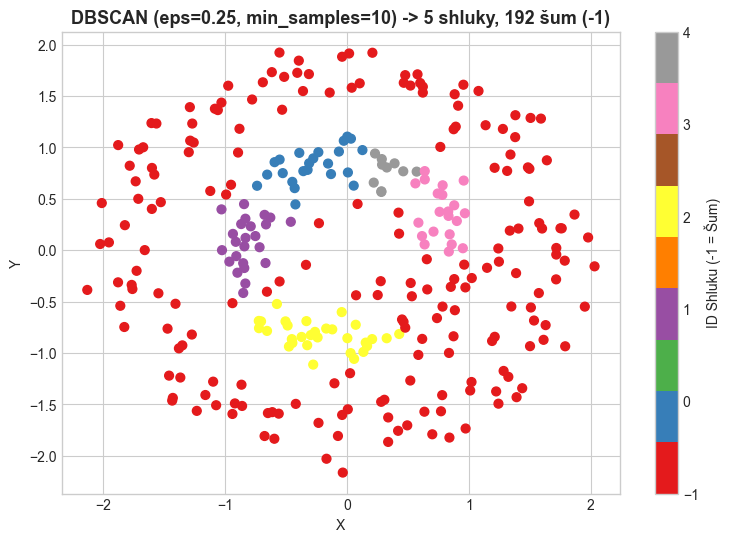

In [5]:
db_2 = DBSCAN(eps=0.25, min_samples=10)
labels_2 = db_2.fit_predict(data_scaled)

n_clusters_2 = len(set(labels_2)) - (1 if -1 in labels_2 else 0)
n_noise_2 = list(labels_2).count(-1)
print(f"Varianta B: Nalezeno shluků: {n_clusters_2}, Detekováno bodů šumu: {n_noise_2}")

plt.figure(figsize=(9, 6))
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c=labels_2, cmap='Set1', s=40)
plt.title(f'DBSCAN (eps=0.25, min_samples=10) -> {n_clusters_2} shluky, {n_noise_2} šum (-1)', fontsize=13, fontweight='bold')
plt.xlabel('X')
plt.ylabel('Y')
plt.colorbar(label='ID Shluku (-1 = Šum)')
plt.show()

---  
### Krok 5: Objektivní určení `eps` pomocí k-NN Distance Elbow grafu
Namísto hádání parametrů spočítáme vzdálenost ke k-tému nejbližšímu sousedovi (kde $k = \text{min\_samples} = 5$). V bodě, kde křivka prudce stoupá nahoru (loket), se nachází optimální hodnota `eps`.

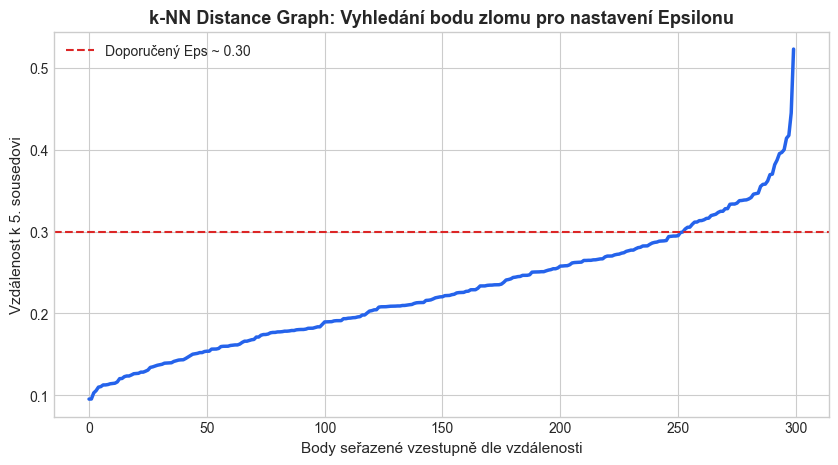

In [6]:
k_neighbors = 5
knn = NearestNeighbors(n_neighbors=k_neighbors)
knn.fit(data_scaled)
distances, _ = knn.kneighbors(data_scaled)

sorted_k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(sorted_k_dist, color='#2563eb', linewidth=2.5)
plt.axhline(y=0.30, color='#dc2626', linestyle='--', label='Doporučený Eps ~ 0.30')
plt.title('k-NN Distance Graph: Vyhledání bodu zlomu pro nastavení Epsilonu', fontsize=13, fontweight='bold')
plt.xlabel('Body seřazené vzestupně dle vzdálenosti', fontsize=11)
plt.ylabel(f'Vzdálenost k {k_neighbors}. sousedovi', fontsize=11)
plt.legend()
plt.show()

---  
### Krok 6: Optimální shlukování DBSCAN (`eps = 0.30, min_samples = 8`)
S optimálním parametrem `eps = 0.30` a `min_samples = 8` DBSCAN dokonale separuje vnitřní a vnější kružnici a odfiltruje extrémní šum.

Optimální DBSCAN: 8 shluky, 79 bodů šumu


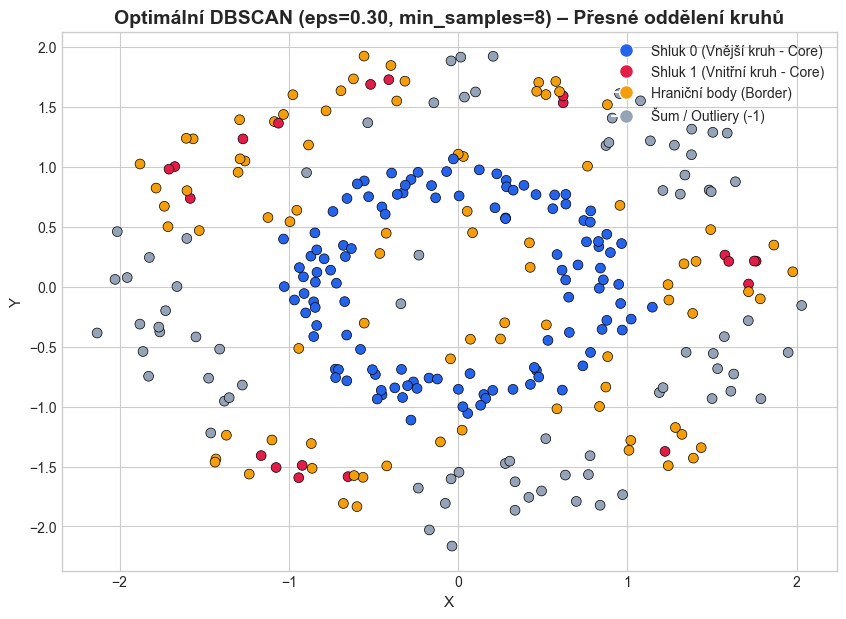

In [7]:
db_opt = DBSCAN(eps=0.30, min_samples=8)
labels_opt = db_opt.fit_predict(data_scaled)

n_clusters_opt = len(set(labels_opt)) - (1 if -1 in labels_opt else 0)
n_noise_opt = list(labels_opt).count(-1)
print(f"Optimální DBSCAN: {n_clusters_opt} shluky, {n_noise_opt} bodů šumu")

# Rozlišení Core, Border a Noise bodů
core_indices = set(db_opt.core_sample_indices_)
point_colors = []
for i, l in enumerate(labels_opt):
    if l == -1:
        point_colors.append('#94a3b8')  # Šum (šedá)
    elif i in core_indices:
        point_colors.append('#2563eb' if l == 0 else '#e11d48')  # Core bod (modrá / červená)
    else:
        point_colors.append('#f59e0b')  # Border bod (žlutá)

plt.figure(figsize=(10, 7))
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c=point_colors, s=50, edgecolors='black', linewidth=0.5)
plt.title(f'Optimální DBSCAN (eps=0.30, min_samples=8) – Přesné oddělení kruhů', fontsize=14, fontweight='bold')
plt.xlabel('X', fontsize=11)
plt.ylabel('Y', fontsize=11)

# Legenda pro typy bodů
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#2563eb', markersize=10, label='Shluk 0 (Vnější kruh - Core)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#e11d48', markersize=10, label='Shluk 1 (Vnitřní kruh - Core)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#f59e0b', markersize=10, label='Hraniční body (Border)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#94a3b8', markersize=10, label='Šum / Outliery (-1)')
]
plt.legend(handles=legend_elements, loc='upper right')
plt.show()

---  
## 🎓 Závěrečné shrnutí (Conclusion)

1. **Proč DBSCAN zvítězil nad K-Means:**
   * K-Means předpokládá konvexní (sférické) shluky a rozděluje prostor lineárními Voroného buňkami. Na soustředných kružnicích je zcela nepoužitelný.
   * DBSCAN využívá lokální hustotu bodů, díky čemuž přirozeně následuje libovolnou geometrii (prstence, půlměsíce, spirály).

2. **Detekce anomálií:**
   * Body ležící v řídkém prostoru byly automaticky izolovány návěštím `-1` bez nutnosti definovat složitá pravidla pro outliery.

3. **Metodická doporučení:**
   * Vždy začínejte standardizací dat (`StandardScaler`).
   * Pro stanovení poloměru $\varepsilon$ používejte **k-NN distance elbow graph**, který eliminuje zdlouhavé zkoušení naslepo.